<a href="https://colab.research.google.com/github/Alinembabazi/AddMatrices-/blob/main/Intro_to_Computer_Vision_Demo_explained.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Computer Vision — Live Demo
**kLab TekHer AI Program · Cohort 2**

In this notebook we follow one image all the way from *raw numbers* to *a model that understands it*:

1. An image is just numbers (pixels and channels)
2. Filters: how a computer finds edges by hand
3. **Classification** — one label for the whole image
4. **Object detection** — what is in the image, and where
5. **Segmentation** — which exact pixels belong to each object
6. Your turn — try your own photo
7. When models fail

> Runs on Google Colab (CPU is enough; Runtime → Change runtime type → T4 GPU makes it faster).

### How to use this notebook
- Run the cells **in order**, from top to bottom (**Shift + Enter**). Later cells use things made in earlier ones.
- Lines that start with `#` are **comments**. Python ignores them; they are there to explain the code to you.
- Each section has a short **The idea** or **What just happened** note (the *why* and the maths) and ends with **Try it yourself**: small changes to make, and what to look for.
- If something breaks: **Runtime → Restart session**, then run all the cells again from the top.

## 0. Setup

In [1]:
# Install Ultralytics: it gives us small, pretrained vision models for classification, detection and segmentation.
# "!" runs a terminal command from the notebook; -q means "quiet" (less text on screen).
!pip install -q ultralytics

import numpy as np                     # NumPy: works with grids of numbers (arrays). An image IS an array.
import matplotlib.pyplot as plt        # Matplotlib: draws images and charts
from PIL import Image                  # PIL (Pillow): opens image files such as .jpg and .png
from ultralytics import YOLO           # YOLO: loads the pretrained models
from ultralytics.utils import ASSETS   # two sample photos ship with the library (bus.jpg and zidane.jpg)

plt.rcParams["figure.dpi"] = 110 # this defines the resolution of the image(figure) in dots per inch (DPI)

# A small helper we reuse in every section: draw one image with a title and no axis rulers.
#   img   : the image (a NumPy array or a PIL image)
#   title : text shown above the image
#   cmap  : colour map for one-channel images, e.g. "gray" (ignored for normal RGB colour images)
#   ax    : which sub-picture to draw in; if None, use the current one
def show(img, title="", cmap=None, ax=None):
    ax = ax or plt.gca()        # plt.gca() = "get current axes" (the current drawing area)
    ax.imshow(img, cmap=cmap)   # turn the numbers back into colours on the screen
    ax.set_title(title)
    ax.axis("off")              # hide the pixel rulers around the picture

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 2.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 1. An image is a grid of numbers

We load a photo and look at what the computer actually receives.
*Tip:* to use your own photo, change `IMAGE_PATH` (or use the upload cell in section 6).

Shape (height, width, channels): (1080, 810, 3)
Data type: uint8 | min: 0 | max: 255
Total numbers in this image: 2,624,400


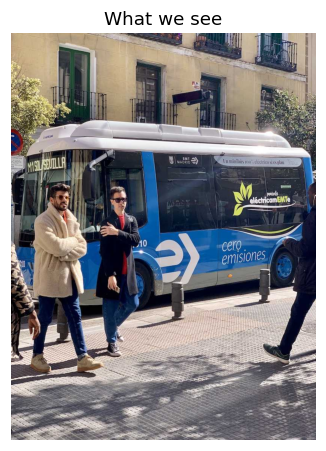

In [2]:
IMAGE_PATH = ASSETS / "bus.jpg"      # a street scene with people and a bus
                                     # ("/" joins the folder and the file name into one path)

# Open the file, make sure it has exactly 3 colour channels (some files are grayscale, or have a 4th
# "transparency" channel), then turn it into a NumPy array of numbers.
img = np.array(Image.open(IMAGE_PATH).convert("RGB"))

# shape = (height, width, channels): rows of pixels, columns of pixels, and 3 colours (R, G, B)
print("Shape (height, width, channels):", img.shape)
# uint8 = "unsigned 8-bit integer": whole numbers from 0 to 255 (8 bits give 2^8 = 256 possible values)
print("Data type:", img.dtype, "| min:", img.min(), "| max:", img.max())
# .size counts every number in the array: height × width × 3
print("Total numbers in this image:", f"{img.size:,}")
show(img, "What we see")
plt.show()

#### What just happened
- The photo is **1080 rows × 810 columns** of pixels, and every pixel has **3 numbers** (red, green, blue).
- So the computer stores $1080 \times 810 \times 3 = 2{,}624{,}400$ numbers. It never sees "a bus", only these numbers.
- `uint8` means each number is a whole number from **0 to 255**. Why 255? Each value uses 8 bits, and 8 bits can hold $2^8 = 256$ different values (0 to 255). 0 = none of that colour, 255 = full.
- Note the order in `shape`: **height first, then width**. Rows go down (y), columns go across (x).

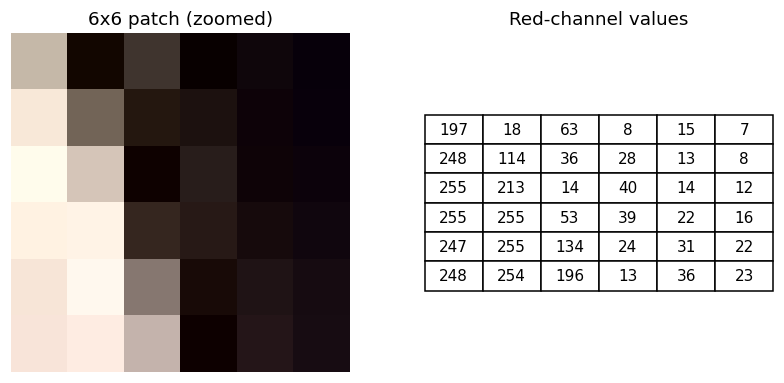

Pixel at (row 648, col 276) = [R, G, B] = [197 184 168]


In [3]:
# Zoom into a tiny 6x6 patch: this is what the computer 'sees'
# pick the 6x6 patch with the most contrast so the numbers are interesting
#   .std() = standard deviation: how much the numbers in a patch differ from each other.
#            A flat patch (one colour) has a std near 0; a patch across an edge has a big std.
#   We test a patch every 12 pixels (the step of range) instead of every pixel, so it runs fast.
#   max(...) compares the tuples (std, row, col) by their first item, so it returns the most contrasty patch.
best = max(((img[r:r+6, c:c+6].std(), r, c) for r in range(0, img.shape[0]-6, 12)
            for c in range(0, img.shape[1]-6, 12)))
_, y, x = best                    # keep the row (y) and column (x); "_" throws the std away
patch = img[y:y+6, x:x+6]         # slicing: rows y to y+5, columns x to x+5, all 3 channels -> shape (6, 6, 3)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))   # 1 row with 2 pictures side by side
show(patch, "6x6 patch (zoomed)", ax=axes[0])
axes[1].axis("off")
axes[1].set_title("Red-channel values")
# patch[:, :, 0] = all rows, all columns, channel 0 (Red) -> a 6x6 grid of numbers, drawn as a table
axes[1].table(cellText=patch[:, :, 0], loc="center", cellLoc="center").scale(1, 1.6)
plt.show()

# img[row, col] gives the 3 numbers of one pixel. Careful: the row (y) comes first, then the column (x).
print(f"Pixel at (row {y}, col {x}) = [R, G, B] =", img[y, x])

#### Reading the numbers
The printed pixel `[197 184 168]` has a lot of red, a lot of green and slightly less blue, so it looks light beige. **High numbers = bright, low numbers = dark.**

**Try it yourself**
- Show the **green** values instead of red: change `patch[:, :, 0]` to `patch[:, :, 1]`.
- Print any pixel you like: `print(img[100, 400])` (row 100, column 400). Is it bright or dark? Check on the photo.
- Change the patch size from `6` to `10` everywhere in the cell. What happens to the table?

In [4]:
axes[1].table(cellText=patch[:, :, 1], loc="center", cellLoc="center").scale(1, 1.6)

In [5]:
print("Pixel at row 100, col 400 = [R, G, B] =", img[100, 400])

Pixel at row 100, col 400 = [R, G, B] = [106  99  91]


### Colour = three channels
Every pixel has a **Red**, a **Green** and a **Blue** value (0–255). Stacked together they make the colour we see.

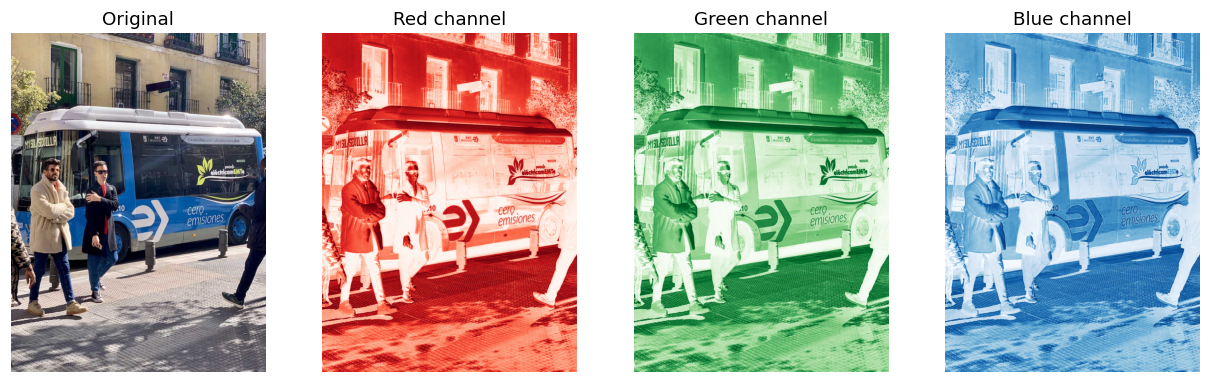

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))   # 1 row with 4 pictures
show(img, "Original", ax=axes[0])
# Loop over the 3 channels. enumerate gives i = 0, 1, 2 together with each (name, colour map) pair.
for i, (name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]):
    # img[:, :, i] keeps only channel i -> a 2-D grid (height × width) with one number per pixel.
    # The colour map paints it: pale = low value (near 0), strong colour = high value (near 255).
    show(img[:, :, i], f"{name} channel", cmap=cmap, ax=axes[i + 1])
plt.show()

#### How to read the channels
In each channel picture, **strong colour = high value** (near 255) and **pale = low value** (near 0).
- White pixels are high in all three channels (255, 255, 255). Black pixels are low in all three (0, 0, 0).
- A red object is strong in the Red channel but pale in Green and Blue.

**Try it yourself**: remove the red channel and see what happens to the colours.
```python
no_red = img.copy()        # copy, so we don't change the original image
no_red[:, :, 0] = 0        # set every Red value to 0
show(no_red, "No red"); plt.show()
```
What colour do the white areas become? *(Hint: white without red = green + blue.)*

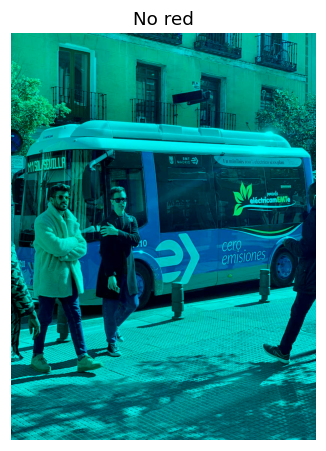

In [7]:
no_red = img.copy()        # copy, so we don't change the original image
no_red[:, :, 0] = 0        # set every Red value to 0
show(no_red, "No red"); plt.show()

## 2. Filters: finding edges by hand

A **filter** (kernel) is a small grid of weights that we slide across the image. Each output pixel is a weighted sum of its neighbours.

- A *blur* filter averages neighbours.
- An *edge* filter (Sobel) subtracts left from right, so it lights up where brightness changes sharply.

A **CNN learns thousands of these filters by itself** from data — that is the whole idea of deep learning for vision.

#### The idea: multiply, then add
Put the kernel on top of a 3×3 patch of pixels. Multiply each pixel by the weight on top of it and add the 9 results. That sum is the new value of the centre pixel. Then move one pixel along and repeat, over the whole image.

$$\text{out}[r, c] = \sum_{i}\sum_{j} \text{kernel}[i, j] \times \text{image}[r+i-1,\; c+j-1]$$

**Worked example with `sobel_x`** (left column −1, −2, −1 · middle column 0 · right column 1, 2, 1):

| Patch | Left side | Right side | Result |
|---|---|---|---|
| Flat: every pixel = 100 | 100 × (−1 −2 −1) = −400 | 100 × (1 + 2 + 1) = +400 | **0** → black, no edge |
| Edge: left = 0, right = 200 | 0 × (−1 −2 −1) = 0 | 200 × (1 + 2 + 1) = +800 | **800** → bright, an edge! |

So `sobel_x` measures **right side minus left side**. It is only big where brightness jumps from left to right, and that is exactly what a **vertical edge** is (the side of the bus, a lamp post, a person's arm).

- **Blur**: 25 weights of 1/25 → the average of 25 neighbours. Sharp details get mixed with their neighbours and fade.
- **Sobel y** is Sobel x flipped with `.T`: **bottom minus top** → horizontal edges (the roof line of the bus).

*Note:* mathematicians call this exact operation *cross-correlation*; in deep learning everyone calls it *convolution*.

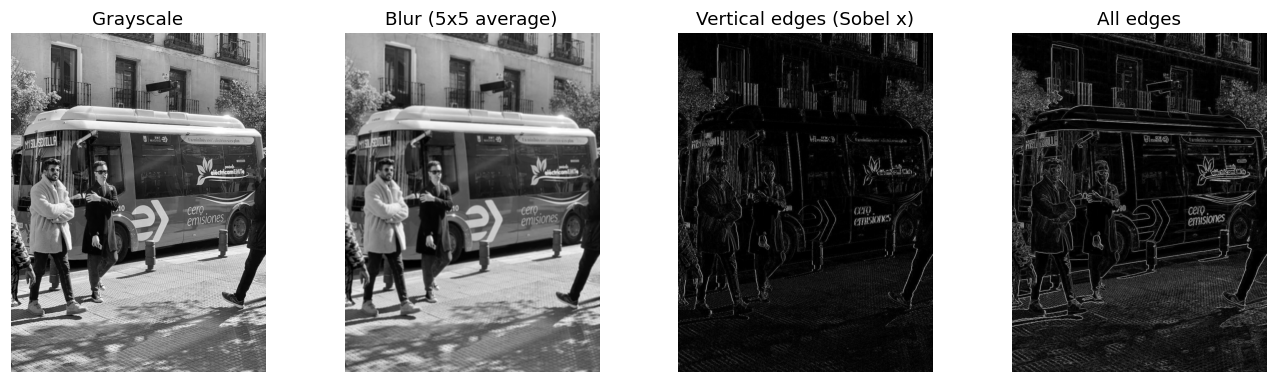

Sobel x kernel:
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]


In [10]:
def convolve(gray, kernel):
    """Slide a small kernel over a grayscale image (the same operation a CNN layer performs)."""
    k = kernel.shape[0]          # kernel size: 3 for a 3x3 kernel, 5 for a 5x5 kernel
    pad = k // 2                 # how far the kernel reaches past its centre: 1 for 3x3, 2 for 5x5
    # Add a border of 'pad' pixels around the image by copying the edge pixels ("edge" mode).
    # Without it the kernel would hang off the image at the borders and the result would be smaller.
    padded = np.pad(gray, pad, mode="edge")
    out = np.zeros_like(gray, dtype=float)   # empty result, same size as the image; float so it can hold negatives
    # Instead of moving the kernel one pixel at a time (very slow in Python), we loop over the k×k WEIGHTS.
    # For each weight we take the whole image shifted by (dy, dx), multiply it by that weight and add it to out.
    # After all k×k weights, every output pixel = sum of (weight × neighbour) — exactly the sliding window,
    # but done with 9 big NumPy steps (for 3x3) instead of one small step for each of the ~875,000 pixels.
    for dy in range(k):
        for dx in range(k):
            out += kernel[dy, dx] * padded[dy:dy + gray.shape[0], dx:dx + gray.shape[1]]
    return out

# Turn the colour image (H, W, 3) into one channel (H, W) by averaging R, G and B for each pixel.
# Edges are about brightness, so one channel is enough. axis=2 means "average across the channels".
gray = img.mean(axis=2)   # simple grayscale: average of R, G, B

# Box blur: a 5x5 grid where every weight is 1/25. Each output pixel = average of its 25 neighbours.
# The weights add up to 1, so the overall brightness stays the same; only fine detail is smoothed away.
blur    = np.ones((5, 5)) / 25
# Sobel x: left column negative, middle column 0, right column positive -> it computes (right side − left side).
# It is big only where brightness changes from left to right = a VERTICAL edge.
# The weights add up to 0, so a flat area gives 0. The middle row has weight 2: the closest pixels count more.
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])   # vertical edges
# .T = transpose (flip over the diagonal): now the top row is negative and the bottom row positive.
# It computes (bottom − top) -> big where brightness changes from top to bottom = a HORIZONTAL edge.
sobel_y = sobel_x.T                                        # horizontal edges

# Combine both directions. np.hypot(a, b) = sqrt(a² + b²), like Pythagoras:
# the strength of the edge whatever its direction (vertical, horizontal or diagonal).
edges = np.hypot(convolve(gray, sobel_x), convolve(gray, sobel_y))

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
show(gray, "Grayscale", cmap="gray", ax=axes[0])
show(convolve(gray, blur), "Blur (5x5 average)", cmap="gray", ax=axes[1])
# np.abs: dark→bright gives a positive number, bright→dark a negative one. Both are edges, so keep only the size.
show(np.abs(convolve(gray, sobel_x)), "Vertical edges (Sobel x)", cmap="gray", ax=axes[2])
show(edges, "All edges", cmap="gray", ax=axes[3])
plt.show()
print("Sobel x kernel:\n", sobel_x)

#### What just happened
- **Blur** looks softer: every pixel is now the average of its neighbours.
- **Vertical edges** shows bright lines where things change from left to right: the sides of the people and the bus.
- **All edges** combines both directions with Pythagoras, $\sqrt{g_x^2 + g_y^2}$ (that is `np.hypot`).
- Why `np.abs`? Dark→bright gives a positive number and bright→dark a negative one. Both are edges, so we keep only the size.
- Why grayscale by a simple average? It is easy to understand. Real photo software uses $0.299R + 0.587G + 0.114B$, because our eyes are most sensitive to green.

**Try it yourself**: make new kernels. *Predict* what each will do first, then run it.
```python
sharpen  = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])   # centre × 5, minus its 4 neighbours
big_blur = np.ones((15, 15)) / 225                          # average of 15 × 15 = 225 neighbours
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
show(convolve(gray, sharpen), "Sharpen", cmap="gray", ax=axes[0])
show(convolve(gray, big_blur), "Big blur", cmap="gray", ax=axes[1])
show(np.abs(convolve(gray, sobel_y)), "Horizontal edges (Sobel y)", cmap="gray", ax=axes[2])
plt.show()
```
- Why do the `sharpen` weights add up to 1, and why does `big_blur` divide by 225? *(So the overall brightness stays the same.)*
- Which edges appear in Sobel y that were missing in Sobel x?

> A CNN does exactly this. The difference: we do not choose the weights — **training learns them** from thousands of labelled images.

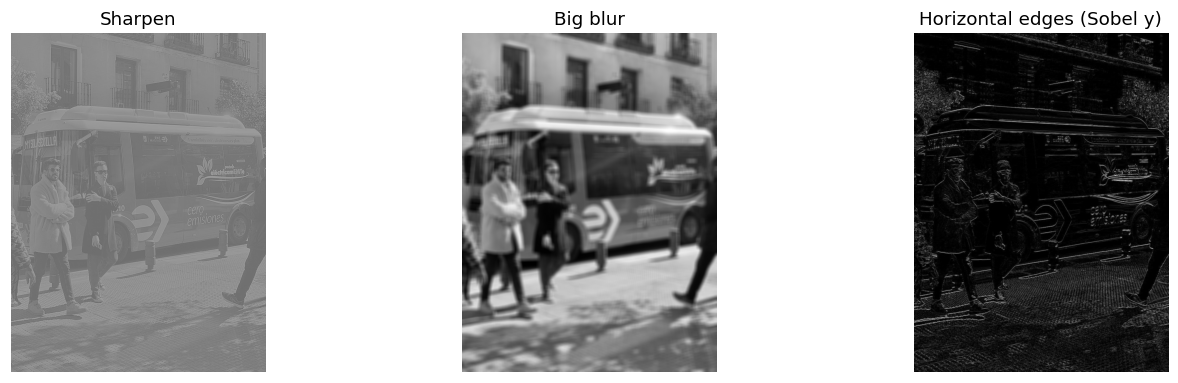

In [11]:
sharpen  = np.array([[ 0,  -1,  0], [-1,  5, -1], [ 0,  -1,  0]])    # center × 5, minus its 4 neighbours
big_blur = np.ones((15, 15)) / 225                              # average of 15 × 15 = 225 neighbours

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
show(convolve(gray, sharpen),  "Sharpen",  cmap="gray", ax=axes[0])
show(convolve(gray, big_blur), "Big blur", cmap="gray", ax=axes[1])
show(np.abs(convolve(gray, sobel_y)), "Horizontal edges (Sobel y)", cmap="gray", ax=axes[2])
plt.show()

## 3. Classification — one label for the whole image

We use a small model pretrained on **ImageNet** (1.2 million photos, 1,000 categories). It returns the most likely labels with a confidence score.

In [13]:
# Load a pretrained classifier. "-cls" = the classification version; "n" = nano, the smallest and fastest size.
# The file is only about 5 MB and downloads automatically the first time.
classifier = YOLO("yolo11n-cls.pt")

def classify(path, top=5):
    # Run the model. It returns a list with one result per image; [0] takes the first (and only) one.
    # verbose=False hides the long log message.
    r = classifier(path, verbose=False)[0]
    # probs = one probability for each of the 1,000 ImageNet classes. Together they add up to 1 (100%).
    probs = r.probs
    print(f"Top-{top} predictions:")
    # probs.top5 = the class numbers of the 5 highest probabilities, highest first (so top can be at most 5)
    for idx in probs.top5[:top]:
        # r.names turns a class number into a word such as "minibus".
        # :<25 pads the name to 25 characters so the columns line up; :6.1% prints 0.571 as 57.1%
        print(f"  {r.names[idx]:<25} {probs.data[idx].item():6.1%}")

classify(IMAGE_PATH)

Top-5 predictions:
  minibus                    57.1%
  police_van                 33.7%
  trolleybus                  4.2%
  recreational_vehicle        1.4%
  streetcar                   0.6%


#### How to read the result
- The model always chooses from its **1,000 ImageNet classes**. There is no class called "street scene", so it picks the closest thing it knows: *minibus*.
- The percentages are **probabilities**. Across all 1,000 classes they add up to 100% (the model's last step, called *softmax*, makes sure of that). Here the top 5 add up to about 97%.
- *police_van* at 33.7% shows the model is unsure between vehicles that look alike. **High confidence does not mean correct**; it only means the model is sure.

**Try it yourself**
- Classify the other sample photo: `classify(ASSETS / "zidane.jpg")`. Is the top label what you would say?
- Look up the list of 1,000 ImageNet classes online. Pick an everyday object in Rwanda that is **not** on the list. What do you think the model will say when it sees one?

In [14]:
classify(ASSETS / "zidane.jpg")

Top-5 predictions:
  suit                       34.7%
  bulletproof_vest            8.5%
  bow_tie                     7.9%
  stage                       7.0%
  rugby_ball                  3.6%


Notice: one label for a whole street scene is not very useful. What we often need to know is **what objects are present and where** → detection.

## 4. Object detection — what and where

The detector draws a **bounding box** around each object it recognises (80 everyday categories from the COCO dataset: people, cars, buses, motorcycles, animals, phones …).

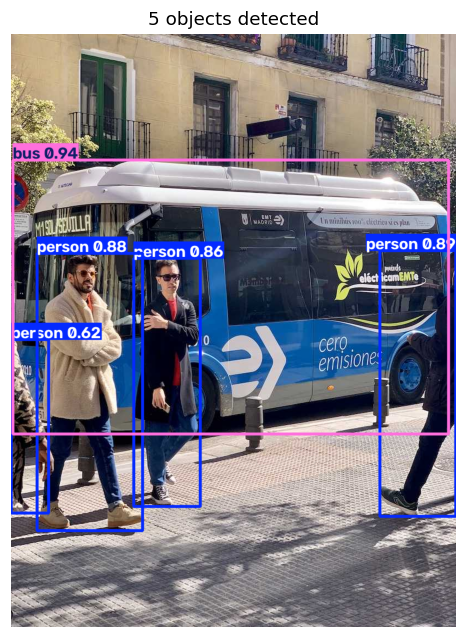

  bus          confidence 94%   box=(3,229)-(796,728)
  person       confidence 89%   box=(671,394)-(809,878)
  person       confidence 88%   box=(47,399)-(239,904)
  person       confidence 86%   box=(223,408)-(344,860)
  person       confidence 62%   box=(0,556)-(68,872)


In [15]:
# "yolo11n.pt" (no suffix) = the detection model, trained on the COCO dataset (80 everyday object types)
detector = YOLO("yolo11n.pt")

def detect(path, conf=0.4):
    # conf=0.4: only keep boxes the model is at least 40% sure about.
    # Lower it -> more boxes but more mistakes; raise it -> fewer boxes that the model is surer about.
    r = detector(path, conf=conf, verbose=False)[0]
    plt.figure(figsize=(7, 7))
    # r.plot() draws the boxes and labels on the image. It returns the colours in BGR order (Blue, Green, Red —
    # the OpenCV convention). [:, :, ::-1] reverses the channel order to RGB, which matplotlib expects.
    show(r.plot()[:, :, ::-1], f"{len(r.boxes)} objects detected")
    plt.show()
    # Every box has a class number (cls), a confidence (conf) and its corner positions (xyxy).
    for box in r.boxes:
        name = r.names[int(box.cls)]
        # xyxy = (x1, y1) the top-left corner and (x2, y2) the bottom-right corner, in pixels.
        # x = column, counted from the left; y = row, counted from the TOP.
        # .int().tolist() turns the PyTorch tensor into 4 plain Python whole numbers.
        x1, y1, x2, y2 = box.xyxy[0].int().tolist()
        print(f"  {name:<12} confidence {float(box.conf):.0%}   box=({x1},{y1})-({x2},{y2})")
    return r        # give the result back so the next cell can reuse it (for counting)

det = detect(IMAGE_PATH)

In [16]:
# Counting is now one line — the basis of traffic counts, crowd monitoring, stock counting ...
from collections import Counter     # Counter counts how many times each item appears
# det.boxes.cls = the class number of every detected box; we turn each one into its name, then count the names.
print(Counter(det.names[int(c)] for c in det.boxes.cls))

Counter({'person': 4, 'bus': 1})


#### How to read the boxes
`bus  confidence 94%  box=(3,229)-(796,728)` means:
- the top-left corner is at x = 3, y = 229 and the bottom-right corner at x = 796, y = 728 (x counts from the left, y from the **top**);
- so the box is $796 - 3 = 793$ pixels wide and $728 - 229 = 499$ pixels tall.
- The person at 62% stands at the very left edge of the photo (x = 0) and is partly cut off, so the model is less sure.

**Why is YOLO fast?** *You Only Look Once*: one pass of the network over the whole image predicts every box, label and confidence together. Older detectors first proposed many regions, then classified each one separately.

**Try it yourself**: the threshold `conf` is a choice *you* make.
```python
_ = detect(IMAGE_PATH, conf=0.1)   # more boxes — are they all correct?
_ = detect(IMAGE_PATH, conf=0.9)   # only very sure boxes — who disappears?
```
This is the same trade-off as in medical screening: a low threshold misses fewer real cases but raises more false alarms.

## 5. Segmentation — which pixels belong to which object

Segmentation goes one step further and labels **every pixel**. This is how satellite models map building footprints or how medical models outline a tumour.

Object pixels cover 44% of the image


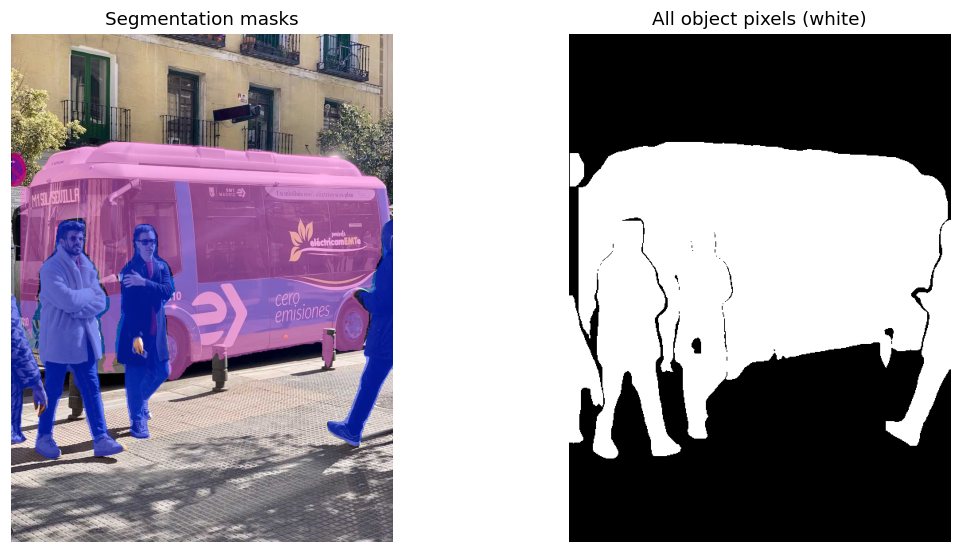

In [17]:
# "-seg" = the segmentation version: for each object it predicts a box AND a mask (which pixels belong to it)
segmenter = YOLO("yolo11n-seg.pt")

r = segmenter(IMAGE_PATH, conf=0.4, verbose=False)[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
# boxes=False: draw only the coloured masks, without rectangles. [:, :, ::-1] = BGR -> RGB, as before.
show(r.plot(boxes=False)[:, :, ::-1], "Segmentation masks", ax=axes[0])
if r.masks is not None:     # if no object was found there are no masks, so we skip this part
    # r.masks.data has shape (number_of_objects, height, width): one grid of 0s and 1s per object
    # (1 = "this pixel belongs to the object"). The grids are at the model's working size, which can be
    # smaller than the photo. .cpu().numpy() turns the PyTorch tensor (maybe on the GPU) into a NumPy array.
    # .max(axis=0) looks through all the masks and keeps 1 wherever ANY object covers the pixel.
    combined = r.masks.data.cpu().numpy().max(axis=0)
    show(combined, "All object pixels (white)", cmap="gray", ax=axes[1])
    # The mean of a grid of 0s and 1s = the fraction of 1s = the share of the image covered by objects.
    print(f"Object pixels cover {combined.mean():.0%} of the image")
plt.show()

#### What just happened
- Each object gets a **mask**: a grid of 0s and 1s, where 1 = "this pixel belongs to the object".
- `.max(axis=0)` combines all the masks: a pixel becomes 1 if *any* object covers it.
- **The mean of 0s and 1s is the fraction of 1s.** For example, the mean of [1, 1, 0, 0] is 0.5 = 50%. That is how we get "Object pixels cover 44% of the image". The same trick measures the area of buildings in satellite images or of a tumour in a scan.

**Try it yourself** (run it straight after the cell above): how many pixels does each object cover?
```python
for mask, c in zip(r.masks.data, r.boxes.cls):
    print(f"{r.names[int(c)]:<10} {int(mask.sum()):>8,} pixels")
```
Which object is the biggest? Does that match the picture? *(The counts are at the model's working size, so they are smaller than in the original photo.)*

In [18]:

for mask, c in zip(r.masks.data, r.boxes.cls):
    print(f"{r.names[int(c)]:<10} {int(mask.sum()):>8,} pixels")


bus          92,230 pixels
person        7,700 pixels
person       17,718 pixels
person       12,328 pixels
stop sign       644 pixels
person        3,946 pixels


## 6. Your turn — try your own photo

Ideas: a market scene, a street in Kigali, a plate of food, your desk, a farm.
Run the cell, click **Choose files**, and pick an image from your computer or phone.

Saving images1.jpeg to images1.jpeg
Top-5 predictions:
  moving_van                 19.4%
  garbage_truck              18.0%
  cab                        14.8%
  trailer_truck              10.8%
  school_bus                  7.0%


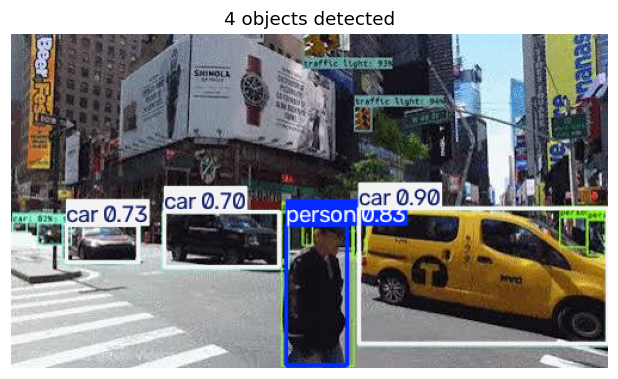

  car          confidence 90%   box=(291,146)-(499,259)
  person       confidence 83%   box=(230,160)-(281,277)
  car          confidence 73%   box=(46,160)-(106,191)
  car          confidence 70%   box=(128,149)-(224,195)


In [19]:
try:
    # files.upload() shows a "Choose files" button. It only exists on Google Colab.
    from google.colab import files
    uploaded = files.upload()          # a dictionary: {file name: file contents}
    MY_IMAGE = next(iter(uploaded))    # take the name of the first uploaded file
except Exception:
    # Not on Colab, or no file chosen: fall back to the second sample photo that ships with Ultralytics.
    print("Not on Colab (or no file chosen) - using the second sample image instead.")
    MY_IMAGE = ASSETS / "zidane.jpg"

# Reuse the functions we wrote above — this is why we packed those steps into functions.
classify(MY_IMAGE)
_ = detect(MY_IMAGE)                   # "_ =" keeps the result quietly; we don't need it here

#### Think about your result
- Did the classifier's top answer make sense? For the sample photo it says *suit* (34.7%): reasonable, but the photo is really "two people".
- Did the detector find everything? What did it miss, and why might that be: lighting, angle, or an object it was never trained on?
- Take a second photo of **the same thing** from another angle or in poor light. Does the answer change?

## 7. When models fail

Models only know what they were trained on. Let's make the image harder: darker, upside down and low resolution — conditions that are common with cheap phones, poor lighting or dusty lenses.

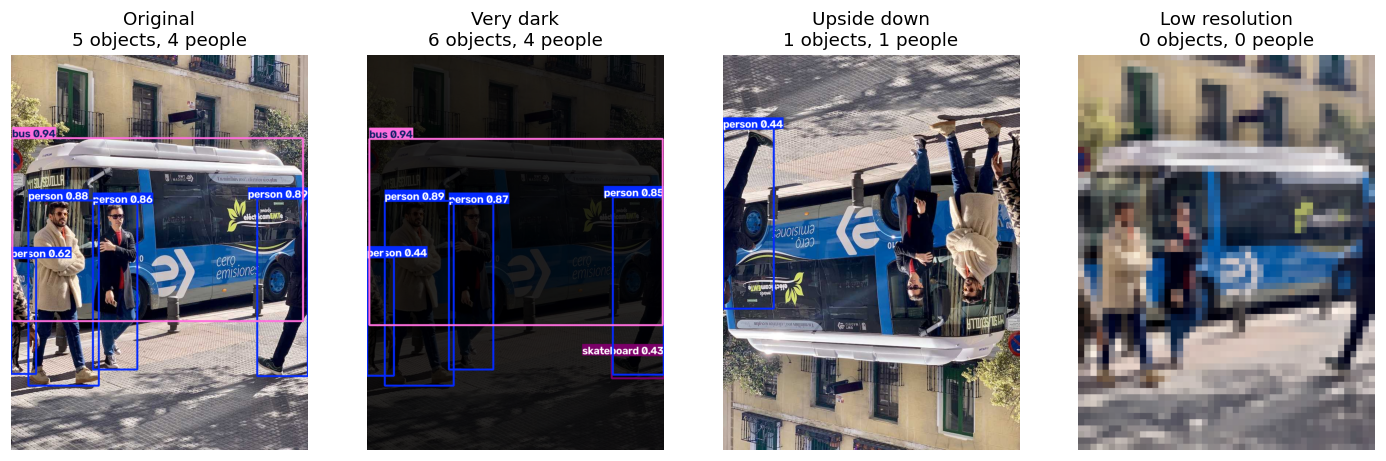

In [20]:
from PIL import ImageEnhance

original = Image.open(IMAGE_PATH).convert("RGB")
# Four versions of the same photo. Each one copies a real-world problem.
variants = {
    "Original":         original,
    # Brightness × 0.15: every pixel value is multiplied by 0.15 (e.g. 200 -> 30). Like a photo taken at night.
    "Very dark":        ImageEnhance.Brightness(original).enhance(0.15),
    # Turned 180°: exactly the same pixels, but in a position the model rarely saw during training.
    "Upside down":      original.rotate(180),
    # Shrink to 48 pixels wide (keeping the shape), then blow it back up to the original size.
    # NEAREST copies each small pixel into a big square block: like a cheap camera or a far-away photo.
    "Low resolution":   original.resize((48, int(48 * original.height / original.width))).resize(original.size, Image.NEAREST),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
# zip pairs each sub-picture (ax) with one (name, image) pair from the dictionary
for ax, (name, im) in zip(axes, variants.items()):
    # np.array(im) is RGB; [:, :, ::-1] flips it to BGR, because Ultralytics treats NumPy arrays as BGR (OpenCV style)
    r = detector(np.array(im)[:, :, ::-1], conf=0.4, verbose=False)[0]   # model expects BGR arrays
    # Count the "person" boxes: True counts as 1 and False as 0, so sum() gives the number of people
    people = sum(r.names[int(c)] == "person" for c in r.boxes.cls)
    show(r.plot()[:, :, ::-1], f"{name}\n{len(r.boxes)} objects, {people} people", ax=ax)
plt.show()

#### Try it yourself: add your own difficulty
1. Add `from PIL import ImageFilter` at the top of the cell above.
2. Add a new line inside `variants = {...}`:
   ```python
   "Blurry":   original.filter(ImageFilter.GaussianBlur(8)),
   ```
3. Change `plt.subplots(1, 4, figsize=(16, 5))` to `plt.subplots(1, 5, figsize=(20, 5))` so there is room for 5 pictures.

Other ideas: `original.rotate(90, expand=True)` (sideways photo), `ImageEnhance.Contrast(original).enhance(0.3)` (dusty lens, low contrast).

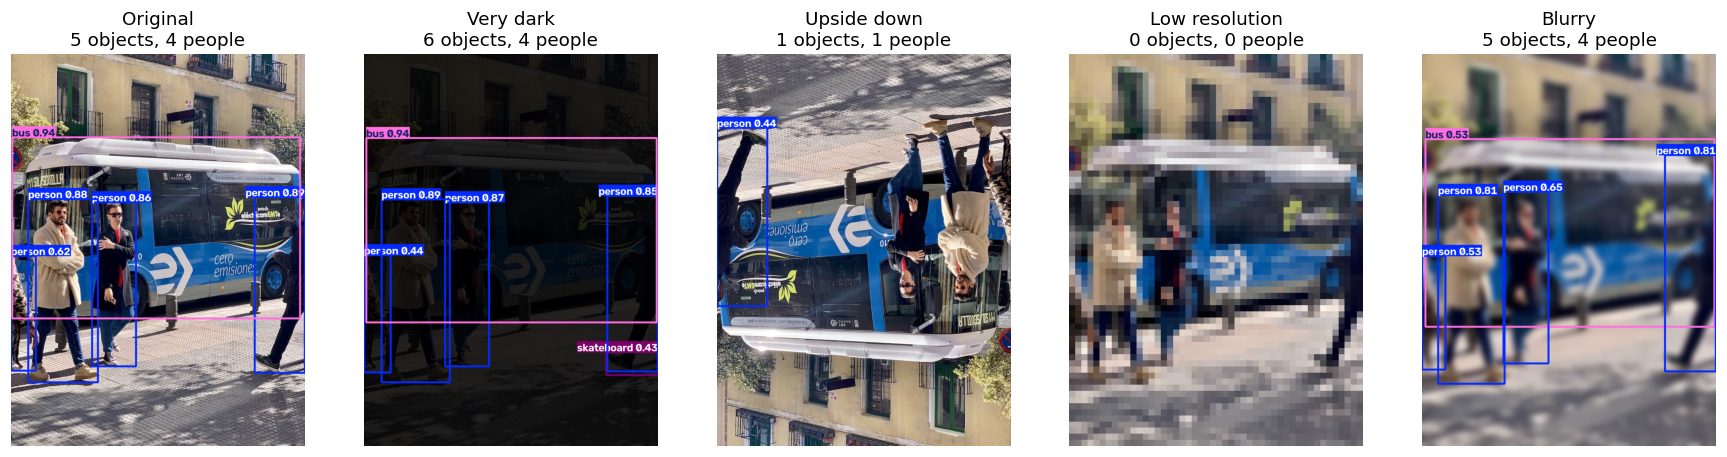

In [21]:
from PIL import ImageEnhance, ImageFilter

original = Image.open(IMAGE_PATH).convert("RGB")

# Four versions of the same photo. Each one copies a real-world problem.
variants = {
    "Original":     original,
    # Brightness × 0.15: every pixel value is multiplied by 0.15 (e.g. 200 -> 30). Like a photo taken at night.
    "Very dark":    ImageEnhance.Brightness(original).enhance(0.15),
    # Turned 180°: exactly the same pixels, but in a position the model rarely saw during training.
    "Upside down":  original.rotate(180),
    # Shrink to 48 pixels wide (keeping the shape), then blow it back up to the original size.
    "Low resolution": original.resize((48, int(48 * original.height / original.width))).resize(original.size, Image.NEAREST),
    # Added blurry variation using a Gaussian blur filter
    "Blurry":       original.filter(ImageFilter.GaussianBlur(8)),
}

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

# zip pairs each sub-picture (ax) with one (name, image) pair from the dictionary
for ax, (name, im) in zip(axes, variants.items()):
    # np.array(im) is RGB; [:, :, ::-1] flips it to BGR, because Ultralytics treats NumPy arrays as BGR (OpenCV style)
    r = detector(np.array(im)[:, :, ::-1], conf=0.4, verbose=False)[0] # model expects BGR arrays
    # Count the "person" boxes: True counts as 1 and False as 0, so sum() gives the number of people
    people = sum(r.names[int(c)] == "person" for c in r.boxes.cls)
    show(r.plot()[:, :, ::-1], f"{name}\n{len(r.boxes)} objects, {people} people", ax=ax)

plt.show()

### Discuss
1. Which change hurt the model most? Why?
2. These models were trained mostly on photos from Europe, North America and Asia. Where might they fail on African images (crops, clothing, roads, skin tones, lighting)?
3. What would you need to fix it? *(Hint: local data + transfer learning — coming later this week.)*

---
**Recap:** image → numbers → filters → learned features → labels, boxes and masks.